In [1]:
import logging
logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
    kamada_kawai_layout ,
)

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_atom, is_superatomic, is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# Linear PAAm homopolymer

In [2]:
num_mols : int = 2
DOP : int = 10

## Assemble MuPT repr

In [3]:
lexicon = {
    'head' : primitive_from_smiles('[H:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]', label="_A"),
    'mid'  : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]', label="_B"),
    'tail' : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[H:2]', label="_C"),
}

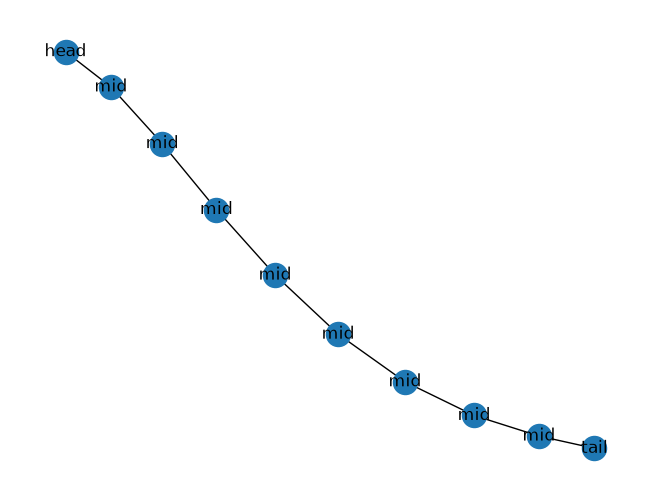

In [4]:
from networkx import get_node_attributes, connected_components
from mupt.graphs.generators import path_graph_from_sequence


label_attr : str = 'label'
sequence_graph = path_graph_from_sequence(
    ['head'] + (DOP - 2)*['mid'] + ['tail'],
    label_attr=label_attr,
)

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, label_attr),
)

### Select, connect, then inspect

In [5]:
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim.parent, CompositePrimitive)
# predicate : NodePredicate[Primitive] = is_superatomic
predicate : NodePredicate[Primitive] = is_atom

In [6]:
molprim_prototype = CompositePrimitive()
molprim_prototype.populate_from_topology_and_lexicon(
    sequence_graph,
    lexicon,
    label_attr=label_attr,
)

system = RootPrimitive(label='system')
for i in range(num_mols):
    molprim = molprim_prototype.copy()
    molprim.label = f'molecule'
    system.attach_child(molprim)

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


In [7]:
xsec = system.cross_section(predicate)
print(f'{len(list(connected_components(xsec)))} molecules')

2 molecules


<Axes: >

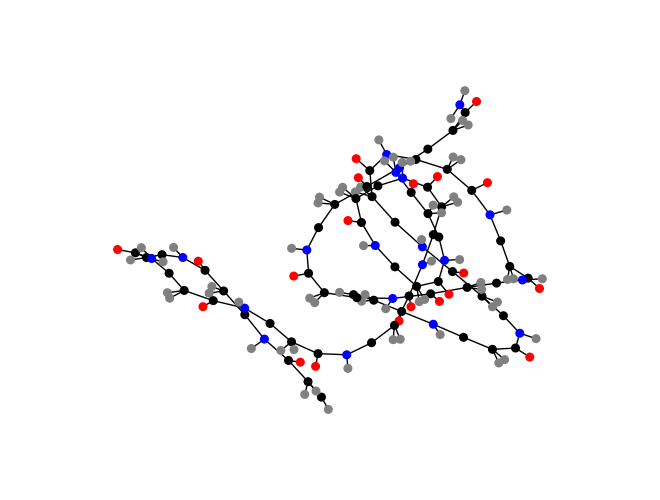

In [8]:
pos = spring_layout(xsec, dim=2)
system.visualize_cross_section(xsec, pos=pos, with_labels=False, node_size=30)

## Export to mbuild

In [9]:
compound = primitive_to_mbuild(
    system,
    predicate=predicate,
    # set False (default) to have Particles directly on Compound
    preserve_intermediates=True, 
)
... # insert downstream code here
print(compound)

<system 164 particles, 162 bonds, non-periodic, id: 6013302976>


In [10]:
# inspect direct descendants of "root" Compound which is returned
display(set(subcomp.name for subcomp in compound.children))

{'molecule'}

from mupt.chemistry.rdkit.depiction import set_rdkdraw_size, hide_atom_indices

set_rdkdraw_size(500, 3/2)
hide_atom_indices()

mols = compound.to_rdkit()
for atom in mols.GetAtoms():
    atom.ClearProp('atomLabel')
display(mols)

In [11]:
print(molprim.hierarchy_summary())

molecule
├── _A
│   ├── H-0
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
╰── _C
    ├── C-1
    ├── C-2
    ├── C-3
    ├── O

In [12]:
from flowermd.library import RandomWalk
import unyt as u

from flowermd.library import GAFF #check which xml your environment is pointing at
import hoomd

from flowermd.library import PhantomWalk

import warnings
import copy
warnings.filterwarnings("ignore")
from flowermd.base import Molecule, Simulation

molecules = Molecule(
    num_mols=1, compound=compound, name="PAAm", identify_connections=False
)

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=1.0,
    base_units=ref_values_dict,
    seed=456,
)

nlist = hoomd.md.nlist.Cell(buffer=0.1, exclusions=["bond"])
system.apply_forcefield(
    force_field=GAFF(), r_cut=1.01, nlist=nlist
)

print(system.all_molecules[0].xyz)
print(system.box)

sim = Simulation(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,  
)

sim.run_NVT(n_steps=2,kT=1.0,tau_kt=1.0,thermalize_particles=False)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


[[-0.17881773 -0.30864365 -2.21669962]
 [-0.50684966  0.61507866 -2.41451807]
 [-0.42361363  1.61019346 -2.36143041]
 [-0.38263745  2.44076589 -1.8060293 ]
 [-1.33798667  2.39973874 -1.51341245]
 [-0.72841369  2.42074146 -0.867926  ]
 [-0.75839652  2.0221028   0.04869184]
 [-1.31384157  1.33636518 -1.99740804]
 [-0.90155121  2.38148288 -2.78177348]
 [-1.36418556 -2.90223377 -0.35119179]
 [-1.91845998  2.1875635  -0.55667332]
 [-2.37845052  1.42035334 -1.0036602 ]
 [-1.9478806   1.84523545 -0.20736582]
 [-1.90109098  1.24310647 -0.14301427]
 [-1.32641045  2.03740676 -0.34006587]
 [-2.577849    2.10872739 -1.30433032]
 [-2.01939055 -2.89130299 -1.12368603]
 [-1.60425928  0.41648037 -0.62111493]
 [-0.87416866 -0.23544733 -0.82595138]
 [-0.12278337  0.04662331 -1.4224883 ]
 [-0.5152191  -0.56462265 -2.10978196]
 [ 0.48683993  0.56796091 -2.01962023]
 [ 1.16494518  0.17944835 -1.39573622]
 [-0.84564672  0.02291215  0.13967633]
 [-1.73682379 -0.72860904 -0.93827969]
 [ 0.54264494 -0.41799442

In [13]:
snap = sim.state.get_snapshot()
system.update_system_positions(snapshot=snap)

In [14]:
snap.particles.position

array([[-0.17924809, -0.30743177, -2.21695912],
       [-0.50680485,  0.61508079, -2.4144908 ],
       [-0.4237512 ,  1.61021034, -2.36139292],
       [-0.38285895,  2.44068338, -1.80591012],
       [-1.33785458,  2.39974446, -1.51345295],
       [-0.72845902,  2.42077344, -0.86786631],
       [-0.75835393,  2.02266899,  0.04739004],
       [-1.31281459,  1.33668113, -1.99782798],
       [-0.90099983,  2.38059304, -2.78128863],
       [-1.36415218, -2.90240024, -0.35128736],
       [-1.91851595,  2.18765211, -0.55681814],
       [-2.37827327,  1.42047703, -1.00337013],
       [-1.94794017,  1.8451767 , -0.20747596],
       [-1.90104537,  1.2431044 , -0.14318272],
       [-1.32722658,  2.0362786 , -0.33978604],
       [-2.57708821,  2.10881842, -1.30346783],
       [-2.01927415, -2.89224616, -1.12303196],
       [-1.60422568,  0.41653095, -0.62106769],
       [-0.87426003, -0.23537744, -0.82589948],
       [-0.12284731,  0.04654931, -1.4226353 ],
       [-0.51516482, -0.5645381 , -2.109

In [15]:
system.all_molecules[0].xyz

array([[-0.17924809, -0.30743177, -2.21695912],
       [-0.50680485,  0.61508079, -2.4144908 ],
       [-0.4237512 ,  1.61021034, -2.36139292],
       [-0.38285895,  2.44068338, -1.80591012],
       [-1.33785458,  2.39974446, -1.51345295],
       [-0.72845902,  2.42077344, -0.86786631],
       [-0.75835393,  2.02266899,  0.04739004],
       [-1.31281459,  1.33668113, -1.99782798],
       [-0.90099983,  2.38059304, -2.78128863],
       [-1.36415218, -2.90240024, -0.35128736],
       [-1.91851595,  2.18765211, -0.55681814],
       [-2.37827327,  1.42047703, -1.00337013],
       [-1.94794017,  1.8451767 , -0.20747596],
       [-1.90104537,  1.2431044 , -0.14318272],
       [-1.32722658,  2.0362786 , -0.33978604],
       [-2.57708821,  2.10881842, -1.30346783],
       [-2.01927415, -2.89224616, -1.12303196],
       [-1.60422568,  0.41653095, -0.62106769],
       [-0.87426003, -0.23537744, -0.82589948],
       [-0.12284731,  0.04654931, -1.4226353 ],
       [-0.51516482, -0.5645381 , -2.109

In [17]:
from gmso.formats.lammpsdata import write_lammpsdata
write_lammpsdata(system.gmso_system, filename="aa-PAAm.lammps", atom_style="full")